## SP-Buy — XGBoost Model Training and Fraud Detection

### Project Background

SP-Buy needs to identify suspicious orders for review. This notebook trains an `XGBoost` classifier to rank orders by their fraud scores and tests how different decision thresholds affect the number of orders flagged.

- **Model input** — Eight order-level features from the cleaned `model_data.csv`.
- **Prediction target** — `is_fraud`, where `1` indicates fraud and `0` indicates a legitimate order.
- **Model selection** — Compare configurations by validation **average precision (AP)**, which measures how well fraud is ranked across thresholds.
- **Threshold selection** — Maximise validation fraud **F1**, then apply the chosen cutoff to later orders in the test period.

### 1️⃣ Imports and Data Preparation

- Use `pandas` and `NumPy` to prepare the data, `scikit-learn` for preprocessing and metrics, and `XGBoost` for classification.
- Set `RANDOM_STATE = 42` for the model and use `0.5` as the shared cutoff for the first comparison.

In [1]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    accuracy_score
)

from xgboost import XGBClassifier
from xgboost.callback import EarlyStopping


RANDOM_STATE = 42
BASELINE_THRESHOLD = 0.5

#### Load and Validate the Cleaned Dataset

- Load **949,872 orders** from `model_data.csv` in the saved run.
- Verify the required columns, valid order dates, unique `(country_code, order_id)` keys and binary fraud labels.
- Treat missing categorical values as `Unknown`. Handle missing numeric values during preprocessing.

| Feature group | Fields |
|---|---|
| **Numeric** | `order_value`, `num_items_ordered`, `days_since_first_order`, `value_per_item` |
| **Categorical** | `country_code`, `collect_type`, `payment_method`, `order_weekday` |

In [2]:
DATA_PATH = Path(r"C:\Users\jxcye\Documents\SP-Buy-Project\model_data.csv")  # Update the path if needed.

TARGET = "is_fraud"
DATE_COLUMN = "order_date"
ORDER_KEYS = ["country_code", "order_id"]

NUMERIC_FEATURES = [
    "order_value",
    "num_items_ordered",
    "days_since_first_order",
    "value_per_item"
]

CATEGORICAL_FEATURES = [
    "country_code",
    "collect_type",
    "payment_method",
    "order_weekday"
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

df = pd.read_csv(
    DATA_PATH,
    dtype={
        "country_code": "string",
        "order_id": "string",
        "customer_id": "string"
    }
)

required_columns = list(dict.fromkeys(
    ORDER_KEYS + [DATE_COLUMN, TARGET] + FEATURES
))

missing_columns = sorted(set(required_columns) - set(df.columns))

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df[DATE_COLUMN] = pd.to_datetime(
    df[DATE_COLUMN],
    errors="raise"
).dt.normalize()

if df[DATE_COLUMN].isna().any():
    raise ValueError("Missing order dates.")

for column in ORDER_KEYS:
    if (
        df[column].isna().any()
        or df[column].str.strip().eq("").any()
    ):
        raise ValueError(f"Missing or blank values in {column}.")

if df.duplicated(ORDER_KEYS).any():
    raise ValueError("Duplicate composite order keys found.")

if df[TARGET].isna().any() or not df[TARGET].isin([0, 1]).all():
    raise ValueError("is_fraud must contain only 0 and 1.")

df[TARGET] = df[TARGET].astype(int)

for column in NUMERIC_FEATURES:
    df[column] = pd.to_numeric(df[column], errors="raise")

if np.isinf(df[NUMERIC_FEATURES].to_numpy(dtype=float)).any():
    raise ValueError("Infinite numeric values found.")

# Standardise categorical missing values for sklearn preprocessing.
for column in CATEGORICAL_FEATURES:
    df[column] = (
        df[column]
        .astype("string")
        .fillna("Unknown")
        .astype(str)
    )

print("Dataset shape:", df.shape)
display(df.head())

display(
    df[FEATURES + [TARGET]]
    .isna()
    .sum()
    .rename("Missing values")
    .to_frame()
)

Dataset shape: (949872, 12)


,country_code,order_id,customer_id,order_date,collect_type,payment_method,order_value,num_items_ordered,is_fraud,days_since_first_order,value_per_item,order_weekday
0,TH,b9ce4cdead,4a2deee064,2022-12-31,delivery,payment on delivery,13.877272,1.0,0,1250.0,13.877272,Saturday
1,MY,eae640c3dd,0e39f85e6d,2023-03-27,delivery,boost wallet,2.512021,1.0,0,8.0,2.512021,Monday
2,PH,6b5eff4d8f,b88034bb7a,2022-11-16,delivery,payment on delivery,4.309368,3.0,0,138.0,1.436456,Wednesday
3,MY,31928238a7,b24be37d24,2023-01-02,delivery,credit card,8.090340,1.0,0,939.0,8.090340,Monday
4,MY,4adec8e335,996287540f,2023-04-02,delivery,Unknown,8.934508,2.0,0,383.0,4.467254,Sunday


,Missing values
order_value,0
num_items_ordered,1
days_since_first_order,876
value_per_item,1
country_code,0
collect_type,0
payment_method,0
order_weekday,0
is_fraud,0


#### Chronological Data Split

- Sort orders by date and choose cutoff dates near the **70%** and **85%** positions.
- Keep all orders from the same day together. This gives an approximately **70/15/15** split and mirrors how the model would be applied to later orders.
- Use the training set to fit the model, validation to guide tuning, and the newest period for final testing.

In [3]:
df = df.sort_values(
    [DATE_COLUMN, "country_code", "order_id"],
    kind="stable"
).reset_index(drop=True)

n_rows = len(df)

validation_start = df.iloc[int(n_rows * 0.70)][DATE_COLUMN]
test_start = df.iloc[int(n_rows * 0.85)][DATE_COLUMN]

if validation_start >= test_start:
    raise ValueError("Not enough distinct dates for this split.")

train_df = df.loc[
    df[DATE_COLUMN] < validation_start
].copy()

val_df = df.loc[
    (df[DATE_COLUMN] >= validation_start)
    & (df[DATE_COLUMN] < test_start)
].copy()

test_df = df.loc[
    df[DATE_COLUMN] >= test_start
].copy()

partitions = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

for name, partition in partitions.items():
    if partition.empty:
        raise ValueError(f"{name} partition is empty.")

    if partition[TARGET].nunique() != 2:
        raise ValueError(f"{name} must contain both classes.")

assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert train_df[DATE_COLUMN].max() < val_df[DATE_COLUMN].min()
assert val_df[DATE_COLUMN].max() < test_df[DATE_COLUMN].min()

split_summary = pd.DataFrame([
    {
        "Partition": name,
        "Orders": len(partition),
        "Dataset percentage": 100 * len(partition) / len(df),
        "Start date": partition[DATE_COLUMN].min(),
        "End date": partition[DATE_COLUMN].max(),
        "Fraud orders": int(partition[TARGET].sum()),
        "Fraud percentage": 100 * partition[TARGET].mean()
    }
    for name, partition in partitions.items()
])

display(split_summary.round(4))

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()

X_val = val_df[FEATURES].copy()
y_val = val_df[TARGET].copy()

X_test = test_df[FEATURES].copy()
y_test = test_df[TARGET].copy()

,Partition,Orders,Dataset percentage,Start date,End date,Fraud orders,Fraud percentage
0,Train,660772,69.5643,2022-11-12,2023-03-14,66847,10.1165
1,Validation,144978,15.2629,2023-03-15,2023-04-13,19740,13.6159
2,Test,144122,15.1728,2023-04-14,2023-05-11,17835,12.3749


#### Data Split Summary

| Partition | Orders | Date range | Fraud rate |
|---|---:|---|---:|
| Training | 660,772 | 12 Nov 2022 – 14 Mar 2023 | 10.12% |
| Validation | 144,978 | 15 Mar – 13 Apr 2023 | 13.62% |
| Test | 144,122 | 14 Apr – 11 May 2023 | 12.37% |

### 2️⃣ Build and Evaluate the Baseline XGBoost Model

XGBoost builds decision trees in sequence. Each new tree adjusts the ensemble's predictions by learning from errors made in earlier rounds. The baseline provides a reference for measuring the effect of tuning.

#### Fit Preprocessing on Training Data

- Fill missing numeric values with the training-set median.
- One-hot encode categorical features and ignore unseen categories when transforming later data.
- Reuse the fitted preprocessor for validation and test. The eight input fields produce **36 encoded features** in the saved run.
- Calculate the training ratio of legitimate to fraudulent orders (**8.8848**) for the fraud-weighting experiment.

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float32
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

X_train_encoded = preprocessor.fit_transform(X_train).astype(
    np.float32
)

X_val_encoded = preprocessor.transform(X_val).astype(
    np.float32
)

feature_names = preprocessor.get_feature_names_out()

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)

training_positives = int(y_train.sum())
training_negatives = int(len(y_train) - training_positives)

fraud_weight_ratio = training_negatives / training_positives

print(f"Training negatives / positives: {fraud_weight_ratio:.4f}")

Encoded training shape: (660772, 36)
Encoded validation shape: (144978, 36)
Training negatives / positives: 8.8848


#### Define Shared Evaluation Metrics

| Metric | What it tells us |
|---|---|
| **Average precision (AP)** | How well the model ranks fraudulent orders across decision thresholds |
| **Fraud precision** | Of the orders flagged, how many were fraudulent |
| **Fraud recall** | Of the fraudulent orders, how many were flagged |
| **Fraud F1** | The harmonic mean of fraud precision and recall |
| **Flagged percentage** | The share of all orders sent for review |
| **Confusion matrix** | Correct predictions, false alerts and missed fraud |

In [5]:
def evaluate_fraud_threshold(
    y_true, scores, threshold, run_name
):
    scores = np.asarray(scores, dtype=float)
    predictions = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Run": run_name,
        "Threshold": float(threshold),

        "Average precision": average_precision_score(
            y_true, scores
        ),
        "Fraud precision": precision_score(
            y_true, predictions,
            pos_label=1, zero_division=0
        ),
        "Fraud recall": recall_score(
            y_true, predictions,
            pos_label=1, zero_division=0
        ),
        "Fraud F1": f1_score(
            y_true, predictions,
            pos_label=1, zero_division=0
        ),

        "Flagged orders": int(predictions.sum()),
        "Flagged percentage": 100 * predictions.mean(),

        "True negatives": int(tn),
        "False positives": int(fp),
        "False negatives": int(fn),
        "True positives": int(tp)
    }


def plot_confusion_matrices(y_true, cases, title):
    """
    cases:
        [(display_name, scores, threshold), ...]
    """
    fig, axes = plt.subplots(
        1, len(cases),
        figsize=(6 * len(cases), 5),
        squeeze=False
    )

    for ax, (name, scores, threshold) in zip(
        axes.ravel(), cases
    ):
        predictions = (
            np.asarray(scores) >= threshold
        ).astype(int)

        ConfusionMatrixDisplay.from_predictions(
            y_true,
            predictions,
            labels=[0, 1],
            display_labels=["Genuine", "Fraud"],
            cmap="Blues",
            values_format="d",
            colorbar=False,
            ax=ax
        )

        ax.set_title(f"{name}\nThreshold = {threshold:.4f}")
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("Actual class")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

#### Baseline Settings and Experiment Setup

| Setting | Baseline value |
|---|---:|
| Boosting rounds | `100` |
| Maximum tree depth | `6` |
| Learning rate | `0.3` |
| Fraud class weight | `1.0` |
| Row and column sampling | `1.0` each |

- Record the training AP, validation AP and validation results at the shared cutoff of `0.5` for each run.
- Rank model configurations by validation AP. Runs with early stopping monitor XGBoost's validation `aucpr` during training, while the experiment table ranks them using scikit-learn's AP.

In [6]:
BASE_PARAMS = {
    "objective": "binary:logistic",
    "n_estimators": 100,
    "max_depth": 6,
    "learning_rate": 0.3,

    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "scale_pos_weight": 1.0,

    "reg_lambda": 1.0,
    "min_child_weight": 1.0,
    "gamma": 0.0,

    "tree_method": "hist",
    "eval_metric": ["logloss", "aucpr"],
    "random_state": RANDOM_STATE,
    "n_jobs": 4
}

experiment_models = {}
experiment_configs = {}
validation_scores = {}
experiment_rows = []


def fit_experiment(
    run_name,
    stage,
    params,
    use_early_stopping=False
):
    if run_name in experiment_models:
        raise ValueError(
            f"{run_name} already exists. "
            "Restart from the experiment-storage cell to rerun."
        )

    model_params = params.copy()

    if use_early_stopping:
        model_params["callbacks"] = [
            EarlyStopping(
                rounds=50,
                metric_name="aucpr",
                data_name="validation_1",
                maximize=True,
                save_best=True
            )
        ]

    model = XGBClassifier(**model_params)

    model.fit(
        X_train_encoded,
        y_train,
        eval_set=[
            (X_train_encoded, y_train),
            (X_val_encoded, y_val)
        ],
        verbose=False
    )

    train_scores = model.predict_proba(
        X_train_encoded
    )[:, 1]

    val_scores = model.predict_proba(
        X_val_encoded
    )[:, 1]

    row = evaluate_fraud_threshold(
        y_val,
        val_scores,
        BASELINE_THRESHOLD,
        run_name
    )

    train_ap = average_precision_score(
        y_train, train_scores
    )

    row.update({
        "Stage": stage,
        "Train AP": train_ap,
        "AP gap": train_ap - row["Average precision"],
        "Trees retained": model.get_booster().num_boosted_rounds(),
        "Max depth": params["max_depth"],
        "Fraud weight": params["scale_pos_weight"],
        "Learning rate": params["learning_rate"],
        "Subsample": params["subsample"],
        "Column sample": params["colsample_bytree"],
        "Early stopping": use_early_stopping
    })

    experiment_models[run_name] = model
    experiment_configs[run_name] = {
        "params": params.copy(),
        "early_stopping": use_early_stopping
    }
    validation_scores[run_name] = val_scores
    experiment_rows.append(row)

    print(
        f"{run_name}: "
        f"AP={row['Average precision']:.4f}, "
        f"F1@0.5={row['Fraud F1']:.4f}, "
        f"trees={row['Trees retained']}"
    )

    return model


def ranked_results():
    return (
        pd.DataFrame(experiment_rows)
        .sort_values(
            ["Average precision", "Run"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )


def best_run_so_far():
    return ranked_results().iloc[0]["Run"]


def show_results():
    columns = [
        "Run", "Stage",
        "Train AP", "Average precision", "AP gap",
        "Fraud precision", "Fraud recall", "Fraud F1",
        "Flagged percentage",
        "False positives", "False negatives",
        "Trees retained"
    ]

    display(ranked_results()[columns].round(4))

#### Train and Evaluate the Baseline

Train `XGB_baseline` for **100 rounds**, then score the validation orders and use the confusion matrix to see how many genuine and fraudulent orders were flagged.

XGB_baseline: AP=0.5282, F1@0.5=0.3049, trees=100


,Run,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged orders,Flagged percentage,True negatives,False positives,False negatives,True positives
0,XGB_baseline,0.5,0.5282,0.6727,0.1972,0.3049,5786,3.991,123344,1894,15848,3892


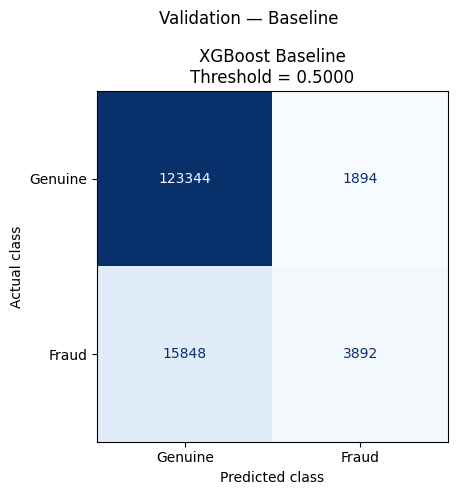

In [7]:
BASELINE_RUN = "XGB_baseline"

xgb_baseline = fit_experiment(
    run_name=BASELINE_RUN,
    stage="Baseline",
    params=BASE_PARAMS,
    use_early_stopping=False
)

baseline_results = pd.DataFrame([
    evaluate_fraud_threshold(
        y_val,
        validation_scores[BASELINE_RUN],
        BASELINE_THRESHOLD,
        BASELINE_RUN
    )
])

display(baseline_results.round(4))

plot_confusion_matrices(
    y_val,
    cases=[
        (
            "XGBoost Baseline",
            validation_scores[BASELINE_RUN],
            BASELINE_THRESHOLD
        )
    ],
    title="Validation — Baseline"
)

#### Baseline Performance Chart

The bar chart shows accuracy alongside fraud precision, recall and F1. With fraud making up **13.62%** of validation orders, recall and the confusion matrix help reveal missed fraud that overall accuracy can hide.

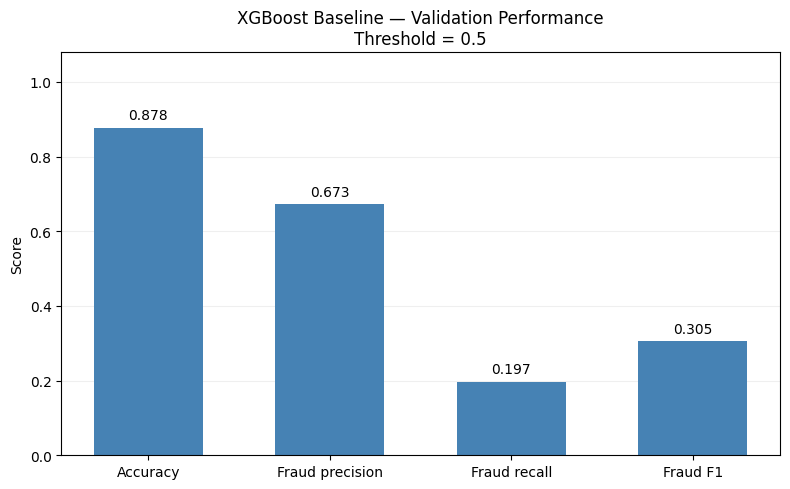

In [8]:
from sklearn.metrics import accuracy_score

baseline_predictions = (
    validation_scores[BASELINE_RUN] >= BASELINE_THRESHOLD
).astype(int)

baseline_row = baseline_results.iloc[0]

metric_labels = [
    "Accuracy", "Fraud precision", "Fraud recall", "Fraud F1"
]

baseline_values = [
    accuracy_score(y_val, baseline_predictions),
    baseline_row["Fraud precision"],
    baseline_row["Fraud recall"],
    baseline_row["Fraud F1"]
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    metric_labels,
    baseline_values,
    color="steelblue",
    width=0.6
)

ax.bar_label(bars, fmt="%.3f", padding=4)

ax.set(
    title="XGBoost Baseline — Validation Performance\nThreshold = 0.5",
    ylabel="Score",
    ylim=(0, 1.08)
)

ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Baseline XGBoost Summary

- The baseline achieved **0.5282 AP** and **0.3049 fraud F1** on validation.
- At the `0.5` cutoff, **67.27%** of flagged orders were fraudulent, but the model caught only **19.72%** of all fraud.
- The model flagged **5,786 orders (3.99%)** and missed **15,848** fraudulent orders. This made fraud recall a priority for the improvement experiments.

### 3️⃣ Model Improvement (Hyperparameter Tuning)

#### Tuning Design

| Stage | Settings tested | Purpose |
|---|---|---|
| **1. Depth and fraud weighting** | Depths `3`, `4`, `6` and weights `1.0`, `3.0`, `8.8848` | Compare tree complexity and how strongly the model learns from fraud cases |
| **2. Slower learning** | Learning rate `0.05`, up to `1,000` rounds and early stopping | Make smaller updates and retain the best round |
| **3. Row and column sampling** | `subsample = 0.8` and `colsample_bytree = 0.8` | Train each tree on a subset of orders and features |
| **4. Regularisation** | `reg_lambda = 5`, `min_child_weight = 5` or `gamma = 1` | Test three ways to constrain tree growth or leaf weights |

Each stage starts from the highest-AP run so far. Stage 1 compares combinations of two settings, and Stage 4 changes one setting at a time from its shared starting configuration.

#### Stage 1 — Tree Depth and Fraud Weighting

- Test eight new combinations. Depth `6` with weight `1.0` is already covered by the baseline.
- Use the training class ratio as the strongest fraud weight to give fraud examples more influence during fitting.

In [9]:
depth_values = [3, 4, 6]

weight_values = {
    "none": 1.0,
    "intermediate": 3.0,
    "training_ratio": float(fraud_weight_ratio)
}

for depth, (weight_name, weight) in product(
    depth_values,
    weight_values.items()
):
    if depth == 6 and weight_name == "none":
        continue

    params = BASE_PARAMS.copy()
    params.update({
        "max_depth": depth,
        "scale_pos_weight": weight
    })

    fit_experiment(
        run_name=f"XGB_depth{depth}_weight_{weight_name}",
        stage="Depth and fraud weighting",
        params=params,
        use_early_stopping=False
    )

show_results()

XGB_depth3_weight_none: AP=0.5311, F1@0.5=0.3012, trees=100
XGB_depth3_weight_intermediate: AP=0.5299, F1@0.5=0.4956, trees=100
XGB_depth3_weight_training_ratio: AP=0.5316, F1@0.5=0.5350, trees=100
XGB_depth4_weight_none: AP=0.5294, F1@0.5=0.2972, trees=100
XGB_depth4_weight_intermediate: AP=0.5293, F1@0.5=0.4926, trees=100
XGB_depth4_weight_training_ratio: AP=0.5289, F1@0.5=0.5386, trees=100
XGB_depth6_weight_intermediate: AP=0.5285, F1@0.5=0.4918, trees=100
XGB_depth6_weight_training_ratio: AP=0.5256, F1@0.5=0.5372, trees=100


,Run,Stage,Train AP,Average precision,AP gap,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Trees retained
0,XGB_depth3_weight_training_ratio,Depth and fraud weighting,0.4341,0.5316,-0.0975,0.4066,0.7820,0.5350,26.1874,22529,4303,100
1,XGB_depth3_weight_none,Depth and fraud weighting,0.4393,0.5311,-0.0918,0.6696,0.1943,0.3012,3.9516,1893,15904,100
2,XGB_depth3_weight_intermediate,Depth and fraud weighting,0.4366,0.5299,-0.0933,0.5860,0.4293,0.4956,9.9760,5988,11265,100
3,XGB_depth4_weight_none,Depth and fraud weighting,0.4483,0.5294,-0.0811,0.6726,0.1907,0.2972,3.8613,1833,15975,100
4,XGB_depth4_weight_intermediate,Depth and fraud weighting,0.4481,0.5293,-0.0811,0.5848,0.4256,0.4926,9.9091,5965,11339,100
5,XGB_depth4_weight_training_ratio,Depth and fraud weighting,0.4453,0.5289,-0.0836,0.4126,0.7753,0.5386,25.5873,21791,4435,100
6,XGB_depth6_weight_intermediate,Depth and fraud weighting,0.4739,0.5285,-0.0547,0.5847,0.4243,0.4918,9.8815,5950,11364,100
7,XGB_baseline,Baseline,0.4752,0.5282,-0.0530,0.6727,0.1972,0.3049,3.9910,1894,15848,100
8,XGB_depth6_weight_training_ratio,Depth and fraud weighting,0.4681,0.5256,-0.0575,0.4135,0.7662,0.5372,25.2280,21450,4615,100


- **Stage 1 result.** Depth `3` with the training-ratio weight achieved the highest validation AP of **0.5316** and moved forward.

#### Stage 2 — Slower Learning and Early Stopping

- Reduce the learning rate from `0.3` to `0.05` and allow up to `1,000` rounds.
- Monitor validation `aucpr`. Stop after **50 rounds** without improvement and retain the best model.

In [10]:
stage2_parent = best_run_so_far()

stage2_params = experiment_configs[
    stage2_parent
]["params"].copy()

stage2_params.update({
    "learning_rate": 0.05,
    "n_estimators": 1000
})

print("Stage 2 parent:", stage2_parent)

fit_experiment(
    run_name="XGB_slow_learning",
    stage="Slower learning and early stopping",
    params=stage2_params,
    use_early_stopping=True
)

show_results()

Stage 2 parent: XGB_depth3_weight_training_ratio
XGB_slow_learning: AP=0.5344, F1@0.5=0.5336, trees=349


,Run,Stage,Train AP,Average precision,AP gap,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Trees retained
0,XGB_slow_learning,Slower learning and early stopping,0.4274,0.5344,-0.1070,0.4040,0.7856,0.5336,26.4723,22872,4233,349
1,XGB_depth3_weight_training_ratio,Depth and fraud weighting,0.4341,0.5316,-0.0975,0.4066,0.7820,0.5350,26.1874,22529,4303,100
2,XGB_depth3_weight_none,Depth and fraud weighting,0.4393,0.5311,-0.0918,0.6696,0.1943,0.3012,3.9516,1893,15904,100
3,XGB_depth3_weight_intermediate,Depth and fraud weighting,0.4366,0.5299,-0.0933,0.5860,0.4293,0.4956,9.9760,5988,11265,100
4,XGB_depth4_weight_none,Depth and fraud weighting,0.4483,0.5294,-0.0811,0.6726,0.1907,0.2972,3.8613,1833,15975,100
5,XGB_depth4_weight_intermediate,Depth and fraud weighting,0.4481,0.5293,-0.0811,0.5848,0.4256,0.4926,9.9091,5965,11339,100
6,XGB_depth4_weight_training_ratio,Depth and fraud weighting,0.4453,0.5289,-0.0836,0.4126,0.7753,0.5386,25.5873,21791,4435,100
7,XGB_depth6_weight_intermediate,Depth and fraud weighting,0.4739,0.5285,-0.0547,0.5847,0.4243,0.4918,9.8815,5950,11364,100
8,XGB_baseline,Baseline,0.4752,0.5282,-0.0530,0.6727,0.1972,0.3049,3.9910,1894,15848,100
9,XGB_depth6_weight_training_ratio,Depth and fraud weighting,0.4681,0.5256,-0.0575,0.4135,0.7662,0.5372,25.2280,21450,4615,100


- **Stage 2 result.** Validation AP increased to **0.5344**, with **349** rounds retained.

#### Stage 3 — Row and Column Sampling

- Sample **80% of training rows** and **80% of features** per boosting round.
- Keep the previous learning rate and early-stopping setup.

In [11]:
stage3_parent = best_run_so_far()

stage3_config = experiment_configs[stage3_parent]
stage3_params = stage3_config["params"].copy()

stage3_params.update({
    "subsample": 0.8,
    "colsample_bytree": 0.8
})

print("Stage 3 parent:", stage3_parent)

fit_experiment(
    run_name="XGB_sampling",
    stage="Row and column sampling",
    params=stage3_params,
    use_early_stopping=stage3_config["early_stopping"]
)

show_results()

Stage 3 parent: XGB_slow_learning
XGB_sampling: AP=0.5358, F1@0.5=0.5292, trees=184


,Run,Stage,Train AP,Average precision,AP gap,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Trees retained
0,XGB_sampling,Row and column sampling,0.4156,0.5358,-0.1202,0.3970,0.7934,0.5292,27.2076,23784,4079,184
1,XGB_slow_learning,Slower learning and early stopping,0.4274,0.5344,-0.1070,0.4040,0.7856,0.5336,26.4723,22872,4233,349
2,XGB_depth3_weight_training_ratio,Depth and fraud weighting,0.4341,0.5316,-0.0975,0.4066,0.7820,0.5350,26.1874,22529,4303,100
3,XGB_depth3_weight_none,Depth and fraud weighting,0.4393,0.5311,-0.0918,0.6696,0.1943,0.3012,3.9516,1893,15904,100
4,XGB_depth3_weight_intermediate,Depth and fraud weighting,0.4366,0.5299,-0.0933,0.5860,0.4293,0.4956,9.9760,5988,11265,100
5,XGB_depth4_weight_none,Depth and fraud weighting,0.4483,0.5294,-0.0811,0.6726,0.1907,0.2972,3.8613,1833,15975,100
6,XGB_depth4_weight_intermediate,Depth and fraud weighting,0.4481,0.5293,-0.0811,0.5848,0.4256,0.4926,9.9091,5965,11339,100
7,XGB_depth4_weight_training_ratio,Depth and fraud weighting,0.4453,0.5289,-0.0836,0.4126,0.7753,0.5386,25.5873,21791,4435,100
8,XGB_depth6_weight_intermediate,Depth and fraud weighting,0.4739,0.5285,-0.0547,0.5847,0.4243,0.4918,9.8815,5950,11364,100
9,XGB_baseline,Baseline,0.4752,0.5282,-0.0530,0.6727,0.1972,0.3049,3.9910,1894,15848,100


- **Stage 3 result.** Sampling increased validation AP to **0.5358**, with **184** rounds retained.

#### Stage 4 — Stronger Regularisation

- `reg_lambda` increases the L2 penalty on leaf weights.
- `min_child_weight` requires more Hessian weight in each child before a split is allowed.
- `gamma` increases the minimum gain required to make a split.
- In the saved run, `RUN_REGULARISATION` is enabled and all three variants start from `XGB_sampling`.

In [12]:
RUN_REGULARISATION = True

if RUN_REGULARISATION:
    regularisation_parent = best_run_so_far()
    parent_config = experiment_configs[regularisation_parent]
    parent_params = parent_config["params"].copy()

    regularisation_changes = {
        "XGB_lambda5": {"reg_lambda": 5.0},
        "XGB_child_weight5": {"min_child_weight": 5.0},
        "XGB_gamma1": {"gamma": 1.0}
    }

    print("Regularisation parent:", regularisation_parent)

    for run_name, changes in regularisation_changes.items():
        params = parent_params.copy()
        params.update(changes)

        fit_experiment(
            run_name=run_name,
            stage="Regularisation",
            params=params,
            use_early_stopping=parent_config["early_stopping"]
        )

    show_results()

Regularisation parent: XGB_sampling
XGB_lambda5: AP=0.5354, F1@0.5=0.5299, trees=202
XGB_child_weight5: AP=0.5361, F1@0.5=0.5302, trees=195
XGB_gamma1: AP=0.5358, F1@0.5=0.5292, trees=184


,Run,Stage,Train AP,Average precision,AP gap,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives,Trees retained
0,XGB_child_weight5,Regularisation,0.4160,0.5361,-0.1200,0.3987,0.7910,0.5302,27.0124,23547,4125,195
1,XGB_gamma1,Regularisation,0.4156,0.5358,-0.1202,0.3970,0.7934,0.5292,27.2076,23784,4079,184
2,XGB_sampling,Row and column sampling,0.4156,0.5358,-0.1202,0.3970,0.7934,0.5292,27.2076,23784,4079,184
3,XGB_lambda5,Regularisation,0.4156,0.5354,-0.1198,0.3985,0.7905,0.5299,27.0096,23553,4135,202
4,XGB_slow_learning,Slower learning and early stopping,0.4274,0.5344,-0.1070,0.4040,0.7856,0.5336,26.4723,22872,4233,349
5,XGB_depth3_weight_training_ratio,Depth and fraud weighting,0.4341,0.5316,-0.0975,0.4066,0.7820,0.5350,26.1874,22529,4303,100
6,XGB_depth3_weight_none,Depth and fraud weighting,0.4393,0.5311,-0.0918,0.6696,0.1943,0.3012,3.9516,1893,15904,100
7,XGB_depth3_weight_intermediate,Depth and fraud weighting,0.4366,0.5299,-0.0933,0.5860,0.4293,0.4956,9.9760,5988,11265,100
8,XGB_depth4_weight_none,Depth and fraud weighting,0.4483,0.5294,-0.0811,0.6726,0.1907,0.2972,3.8613,1833,15975,100
9,XGB_depth4_weight_intermediate,Depth and fraud weighting,0.4481,0.5293,-0.0811,0.5848,0.4256,0.4926,9.9091,5965,11339,100


- **Stage 4 result.** Increasing `min_child_weight` to `5` gave the highest validation AP of **0.5361** and retained **195** rounds. The gain over sampling alone was **0.0003 AP**.

### 4️⃣ Compare the Baseline and Selected Model on Validation

#### Select the Configuration by Validation Average Precision

`XGB_child_weight5` ranked first by validation AP. It used depth `3`, a fraud weight of about `8.8848`, a learning rate of `0.05`, row and column sampling of `0.8`, and `min_child_weight = 5`.

In [13]:
xgb_improvement_results = ranked_results()

selected_xgb_run = xgb_improvement_results.iloc[0]["Run"]
selected_xgb_model = experiment_models[selected_xgb_run]
selected_xgb_scores = validation_scores[selected_xgb_run]

print("Selected configuration:", selected_xgb_run)

if selected_xgb_run == BASELINE_RUN:
    print(
        "The baseline remained best by validation average precision. "
        "The improvement experiments did not establish a better configuration."
    )

display(
    xgb_improvement_results[[
        "Run",
        "Average precision",
        "Fraud precision",
        "Fraud recall",
        "Fraud F1",
        "Flagged percentage",
        "False positives",
        "False negatives"
    ]].round(4)
)

Selected configuration: XGB_child_weight5


,Run,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives
0,XGB_child_weight5,0.5361,0.3987,0.7910,0.5302,27.0124,23547,4125
1,XGB_gamma1,0.5358,0.3970,0.7934,0.5292,27.2076,23784,4079
2,XGB_sampling,0.5358,0.3970,0.7934,0.5292,27.2076,23784,4079
3,XGB_lambda5,0.5354,0.3985,0.7905,0.5299,27.0096,23553,4135
4,XGB_slow_learning,0.5344,0.4040,0.7856,0.5336,26.4723,22872,4233
5,XGB_depth3_weight_training_ratio,0.5316,0.4066,0.7820,0.5350,26.1874,22529,4303
6,XGB_depth3_weight_none,0.5311,0.6696,0.1943,0.3012,3.9516,1893,15904
7,XGB_depth3_weight_intermediate,0.5299,0.5860,0.4293,0.4956,9.9760,5988,11265
8,XGB_depth4_weight_none,0.5294,0.6726,0.1907,0.2972,3.8613,1833,15975
9,XGB_depth4_weight_intermediate,0.5293,0.5848,0.4256,0.4926,9.9091,5965,11339


#### Compare Both Models at a Fixed Cutoff of 0.5

Use the same validation orders and decision threshold for both models. The confusion matrices show how each configuration trades off false alerts against missed fraud.

,Run,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged orders,Flagged percentage,True negatives,False positives,False negatives,True positives,Model,Experiment
0,XGB_baseline,0.5,0.5282,0.6727,0.1972,0.3049,5786,3.9910,123344,1894,15848,3892,Baseline,Fixed threshold 0.5
1,XGB_child_weight5,0.5,0.5361,0.3987,0.7910,0.5302,39162,27.0124,101691,23547,4125,15615,Selected configuration,Fixed threshold 0.5


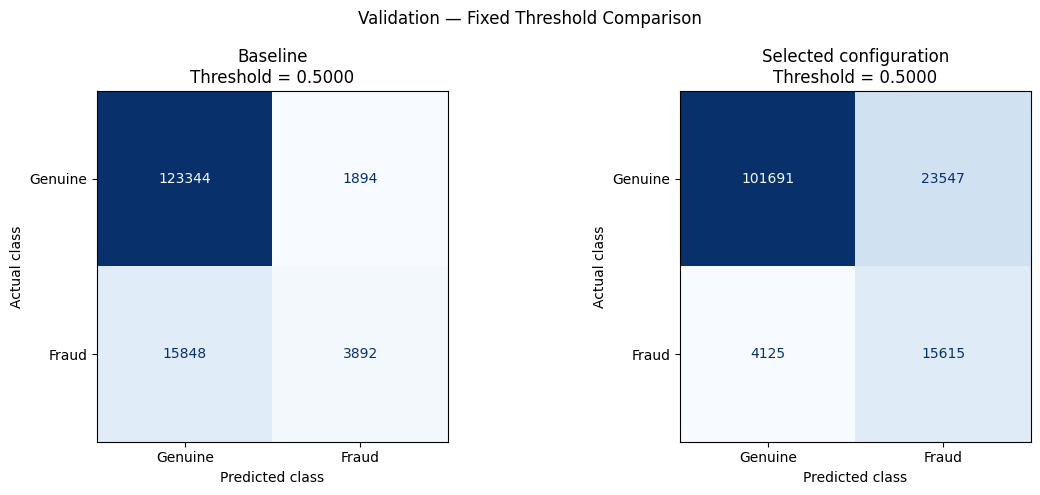

In [14]:
comparison_scores = {
    "Baseline": validation_scores[BASELINE_RUN],
    "Selected configuration": selected_xgb_scores
}

fixed_rows = []

for name, scores in comparison_scores.items():
    row = evaluate_fraud_threshold(
        y_val,
        scores,
        BASELINE_THRESHOLD,
        run_name=(
            BASELINE_RUN
            if name == "Baseline"
            else selected_xgb_run
        )
    )

    row["Model"] = name
    row["Experiment"] = "Fixed threshold 0.5"
    fixed_rows.append(row)

fixed_results = pd.DataFrame(fixed_rows)

display(fixed_results.round(4))

plot_confusion_matrices(
    y_val,
    cases=[
        (name, scores, BASELINE_THRESHOLD)
        for name, scores in comparison_scores.items()
    ],
    title="Validation — Fixed Threshold Comparison"
)

#### Baseline vs Selected Configuration — Performance Chart

| Validation metric at `0.5` | Baseline | Selected |
|---|---:|---:|
| Average precision | 0.5282 | **0.5361** |
| Fraud precision | **0.6727** | 0.3987 |
| Fraud recall | 0.1972 | **0.7910** |
| Fraud F1 | 0.3049 | **0.5302** |
| Orders flagged | 3.99% | 27.01% |
| False positives | 1,894 | 23,547 |
| False negatives | 15,848 | 4,125 |

- The selected configuration caught **11,723 more fraudulent orders** and generated **21,653 more false alerts** at the default cutoff.
- The **0.0079 AP** gain shows a modest ranking improvement. The larger difference at `0.5` reflects how differently the two models flag orders at that cutoff.

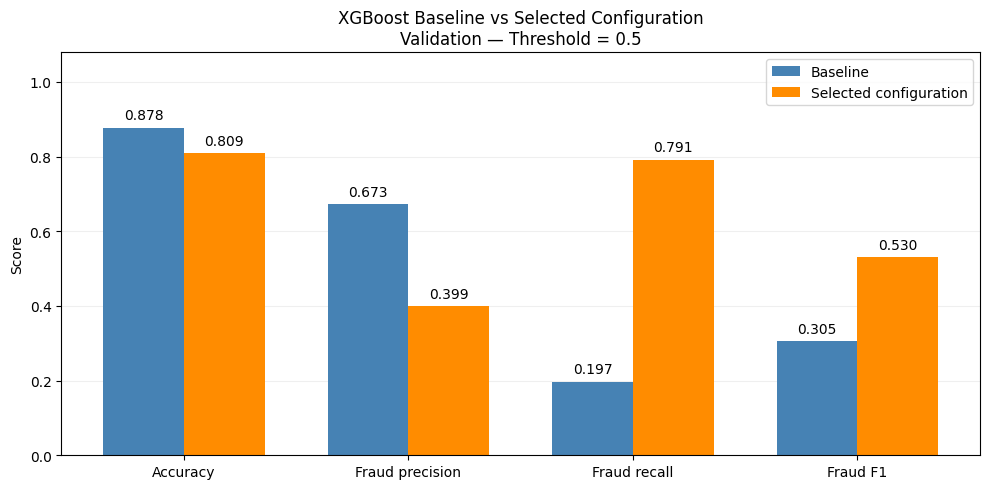

In [15]:
comparison_values = {}

for name, scores in comparison_scores.items():
    predictions = (
        scores >= BASELINE_THRESHOLD
    ).astype(int)

    row = fixed_results.loc[
        fixed_results["Model"] == name
    ].iloc[0]

    comparison_values[name] = [
        accuracy_score(y_val, predictions),
        row["Fraud precision"],
        row["Fraud recall"],
        row["Fraud F1"]
    ]

x = np.arange(len(metric_labels))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))

baseline_bars = ax.bar(
    x - width / 2,
    comparison_values["Baseline"],
    width,
    label="Baseline",
    color="steelblue"
)

selected_bars = ax.bar(
    x + width / 2,
    comparison_values["Selected configuration"],
    width,
    label="Selected configuration",
    color="darkorange"
)

ax.bar_label(baseline_bars, fmt="%.3f", padding=4)
ax.bar_label(selected_bars, fmt="%.3f", padding=4)

ax.set_xticks(x)
ax.set_xticklabels(metric_labels)

ax.set(
    title="XGBoost Baseline vs Selected Configuration\n"
          "Validation — Threshold = 0.5",
    ylabel="Score",
    ylim=(0, 1.08)
)

ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()

#### Training and Validation Learning Curves

- Compare **log loss** and XGBoost's **`aucpr`** across boosting rounds.
- Lower log loss and higher `aucpr` indicate better performance on their respective metrics.
- The dashed line marks the round selected by validation `aucpr` (**round 195** in the saved run).

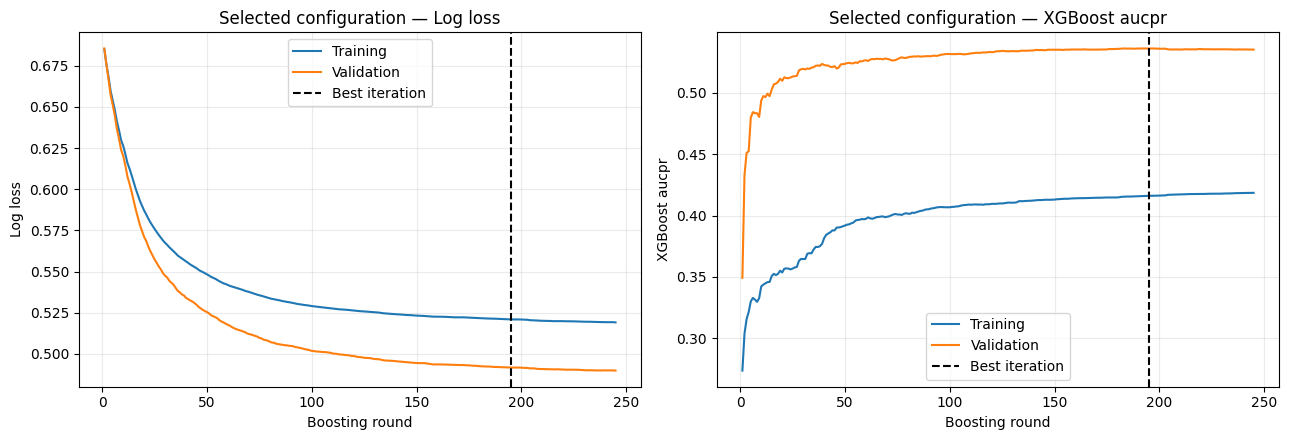

In [16]:
history = selected_xgb_model.evals_result()
selected_config = experiment_configs[selected_xgb_run]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, metric, ylabel in zip(
    axes,
    ["logloss", "aucpr"],
    ["Log loss", "XGBoost aucpr"]
):
    train_values = history["validation_0"][metric]
    val_values = history["validation_1"][metric]

    rounds = np.arange(1, len(train_values) + 1)

    ax.plot(rounds, train_values, label="Training")
    ax.plot(rounds, val_values, label="Validation")

    if selected_config["early_stopping"]:
        ax.axvline(
            selected_xgb_model.best_iteration + 1,
            color="black",
            linestyle="--",
            label="Best iteration"
        )

    ax.set(
        title=f"Selected configuration — {ylabel}",
        xlabel="Boosting round",
        ylabel=ylabel
    )
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

### 5️⃣ Separate Experiment — Tune the Decision Threshold

- Reuse the validation fraud scores from both trained models.
- Search for the cutoff that maximises **fraud F1** for each model. When several thresholds give the same maximum F1, choose the highest one.
- Changing the cutoff changes which orders are flagged. The ranking of scores and AP stay the same for each model on that dataset.

In [17]:
def threshold_search(y_true, scores):
    scores = np.asarray(scores, dtype=float)

    precision, recall, thresholds = precision_recall_curve(
        y_true, scores
    )

    # The final precision/recall pair has no threshold.
    precision = precision[:-1]
    recall = recall[:-1]

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision),
        where=(precision + recall) > 0
    )

    # Exact F1 ties: prefer the highest threshold.
    best_positions = np.flatnonzero(f1 == f1.max())
    best_position = best_positions[-1]

    best_threshold = float(thresholds[best_position])

    flagged = len(scores) - np.searchsorted(
        np.sort(scores),
        thresholds,
        side="left"
    )

    curve = pd.DataFrame({
        "Threshold": thresholds,
        "Fraud precision": precision,
        "Fraud recall": recall,
        "Fraud F1": f1,
        "Flagged orders": flagged,
        "Flagged percentage": 100 * flagged / len(scores)
    })

    return best_threshold, curve


tuned_thresholds = {}
threshold_curves = {}
tuned_rows = []

for name, scores in comparison_scores.items():
    threshold, curve = threshold_search(y_val, scores)

    tuned_thresholds[name] = threshold
    threshold_curves[name] = curve

    row = evaluate_fraud_threshold(
        y_val,
        scores,
        threshold,
        run_name=(
            BASELINE_RUN
            if name == "Baseline"
            else selected_xgb_run
        )
    )

    row["Model"] = name
    row["Experiment"] = "Threshold tuned for validation F1"
    tuned_rows.append(row)

    print(f"{name}: threshold = {threshold:.6f}")

tuned_results = pd.DataFrame(tuned_rows)

full_comparison = pd.concat(
    [fixed_results, tuned_results],
    ignore_index=True
)

comparison_columns = [
    "Model",
    "Run",
    "Experiment",
    "Threshold",
    "Average precision",
    "Fraud precision",
    "Fraud recall",
    "Fraud F1",
    "Flagged percentage",
    "False positives",
    "False negatives"
]

display(full_comparison[comparison_columns].round(4))

selected_xgb_threshold = tuned_thresholds[
    "Selected configuration"
]

Baseline: threshold = 0.141980
Selected configuration: threshold = 0.619079


,Model,Run,Experiment,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives
0,Baseline,XGB_baseline,Fixed threshold 0.5,0.5000,0.5282,0.6727,0.1972,0.3049,3.9910,1894,15848
1,Selected configuration,XGB_child_weight5,Fixed threshold 0.5,0.5000,0.5361,0.3987,0.7910,0.5302,27.0124,23547,4125
2,Baseline,XGB_baseline,Threshold tuned for validation F1,0.1420,0.5282,0.4632,0.6928,0.5552,20.3631,15847,6065
3,Selected configuration,XGB_child_weight5,Threshold tuned for validation F1,0.6191,0.5361,0.4708,0.6873,0.5588,19.8761,15249,6173


#### Validation Results After Threshold Tuning

| Model | Tuned cutoff | Fraud precision | Fraud recall | Fraud F1 | Orders flagged |
|---|---:|---:|---:|---:|---:|
| Baseline | 0.1420 | 0.4632 | 0.6928 | 0.5552 | 20.36% |
| Selected | 0.6191 | 0.4708 | 0.6873 | **0.5588** | 19.88% |

- Lowering the baseline cutoff raised recall from **19.72% to 69.28%**, with more false alerts.
- Raising the selected model's cutoff reduced its flagged share from **27.01% to 19.88%** and reduced false positives from **23,547 to 15,249**, with lower recall.
- The tuned confusion matrices show that the two models operated at a much closer review volume after threshold tuning.

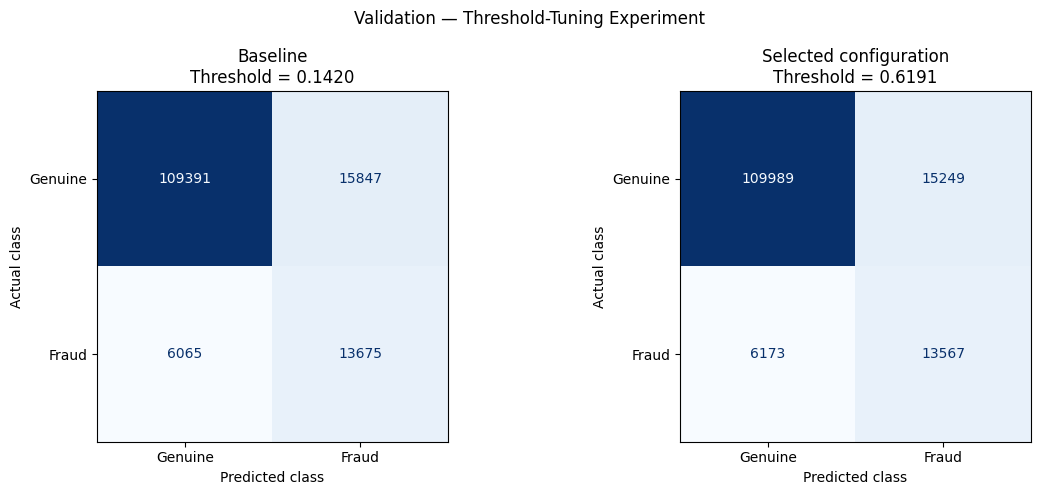

In [18]:
plot_confusion_matrices(
    y_val,
    cases=[
        (
            name,
            scores,
            tuned_thresholds[name]
        )
        for name, scores in comparison_scores.items()
    ],
    title="Validation — Threshold-Tuning Experiment"
)

#### Precision, Recall and F1 Across Thresholds

- The dotted line marks the shared cutoff of `0.5`. The dashed line marks the F1-maximising cutoff for each model.
- Read the curves at either line to see how the review decision changes the balance between catching fraud and generating false alerts.

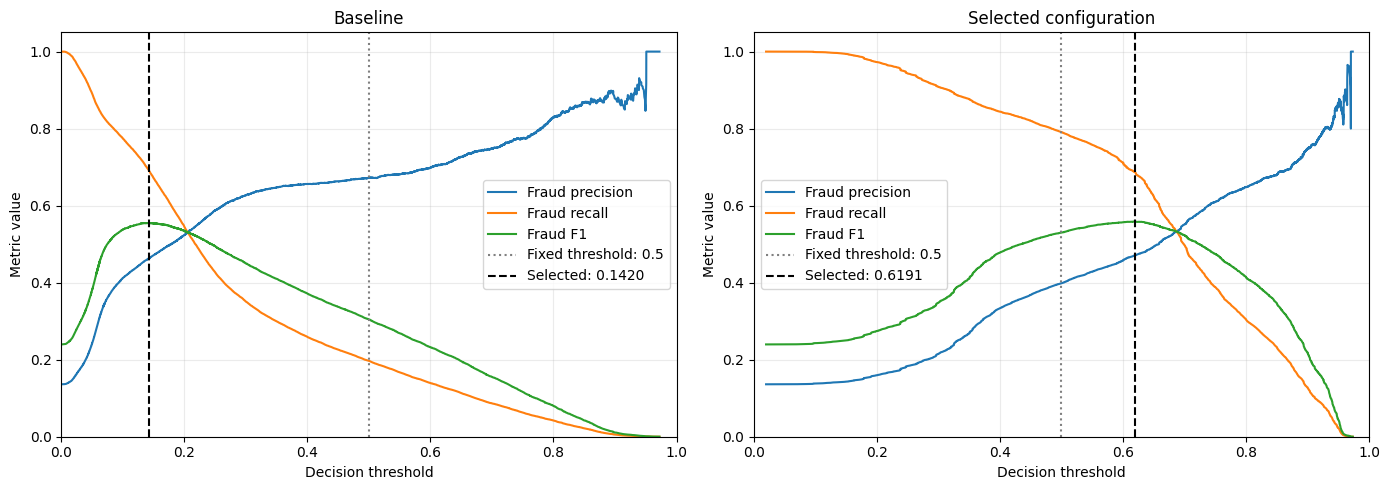

In [19]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for ax, (name, curve) in zip(
    axes, threshold_curves.items()
):
    for metric in [
        "Fraud precision",
        "Fraud recall",
        "Fraud F1"
    ]:
        ax.plot(
            curve["Threshold"],
            curve[metric],
            label=metric
        )

    ax.axvline(
        BASELINE_THRESHOLD,
        color="grey",
        linestyle=":",
        label="Fixed threshold: 0.5"
    )

    ax.axvline(
        tuned_thresholds[name],
        color="black",
        linestyle="--",
        label=f"Selected: {tuned_thresholds[name]:.4f}"
    )

    ax.set(
        title=name,
        xlabel="Decision threshold",
        ylabel="Metric value",
        xlim=(0, 1),
        ylim=(0, 1.05)
    )

    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

#### Precision–Recall Comparison

- Compare the full validation precision–recall curves to assess the models' rankings across cutoffs.
- The dots mark the tuned operating points. The horizontal reference line shows the **13.62%** validation fraud prevalence.

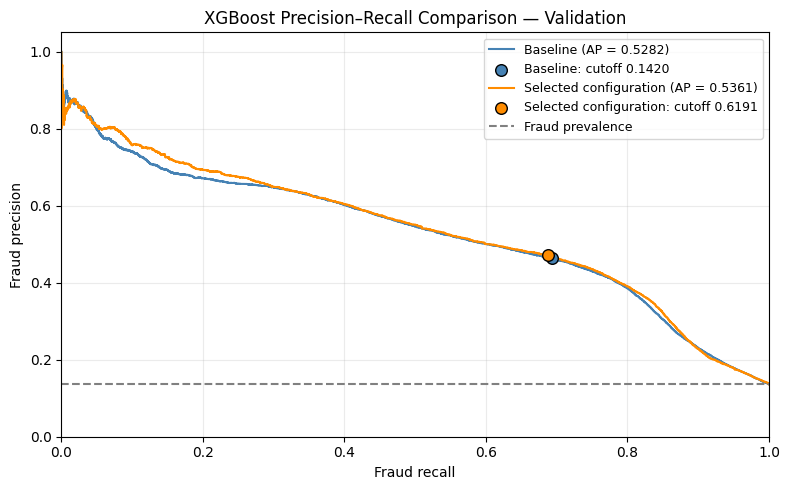

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

colors = {
    "Baseline": "steelblue",
    "Selected configuration": "darkorange"
}

for name, scores in comparison_scores.items():
    precision, recall, _ = precision_recall_curve(
        y_val, scores
    )

    ap = average_precision_score(y_val, scores)

    ax.step(
        recall,
        precision,
        where="post",
        color=colors[name],
        label=f"{name} (AP = {ap:.4f})"
    )

    predictions = (
        scores >= tuned_thresholds[name]
    ).astype(int)

    ax.scatter(
        recall_score(y_val, predictions, zero_division=0),
        precision_score(y_val, predictions, zero_division=0),
        color=colors[name],
        edgecolor="black",
        s=70,
        zorder=3,
        label=f"{name}: cutoff {tuned_thresholds[name]:.4f}"
    )

ax.axhline(
    y_val.mean(),
    color="grey",
    linestyle="--",
    label="Fraud prevalence"
)

ax.set(
    title="XGBoost Precision–Recall Comparison — Validation",
    xlabel="Fraud recall",
    ylabel="Fraud precision",
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.grid(alpha=0.25)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### 6️⃣ Final Evaluation on Unseen Orders

- Use the newest orders from **14 April to 11 May 2023** as the final test set.
- Apply the already fitted preprocessor and score each order with both trained models.
- Evaluate both models at `0.5` and at their validation-selected thresholds. Carry the thresholds forward as selected on validation.

,Model,Run,Experiment,Threshold,Average precision,Fraud precision,Fraud recall,Fraud F1,Flagged percentage,False positives,False negatives
0,Baseline,XGB_baseline,Fixed threshold 0.5,0.5000,0.4219,0.5310,0.2168,0.3079,5.0534,3416,13968
1,Baseline,XGB_baseline,Validation-selected threshold,0.1420,0.4219,0.3642,0.6664,0.4710,22.6405,20745,5950
2,Selected configuration,XGB_child_weight5,Fixed threshold 0.5,0.5000,0.4275,0.3111,0.7511,0.4400,29.8747,29660,4439
3,Selected configuration,XGB_child_weight5,Validation-selected threshold,0.6191,0.4275,0.3709,0.6599,0.4749,22.0182,19963,6065


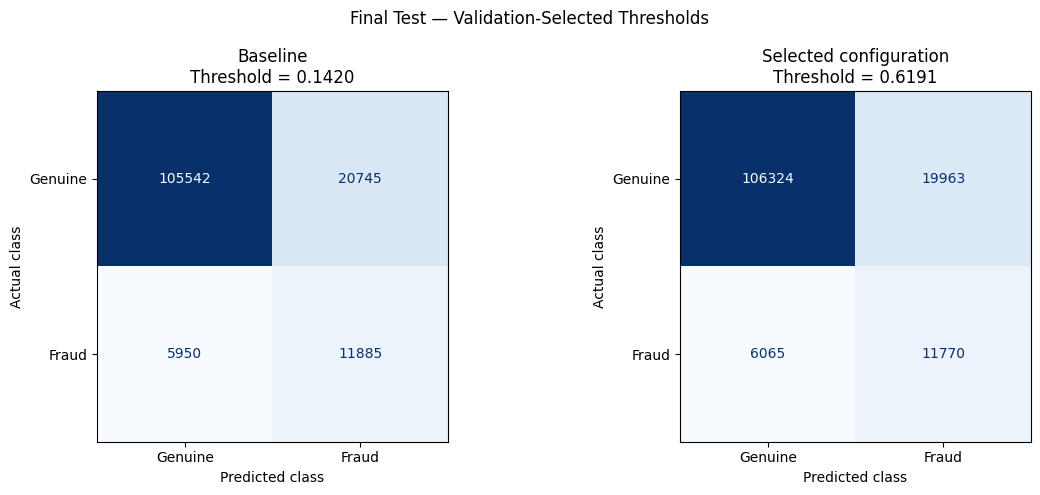

In [21]:
RUN_FINAL_TEST = True # Set to True to run the final test evaluation.

if RUN_FINAL_TEST:
    X_test_encoded = preprocessor.transform(
        X_test
    ).astype(np.float32)

    test_score_dict = {
        "Baseline": xgb_baseline.predict_proba(
            X_test_encoded
        )[:, 1],
        "Selected configuration": selected_xgb_model.predict_proba(
            X_test_encoded
        )[:, 1]
    }

    test_rows = []

    for name, scores in test_score_dict.items():
        run_name = (
            BASELINE_RUN
            if name == "Baseline"
            else selected_xgb_run
        )

        for experiment, threshold in [
            ("Fixed threshold 0.5", BASELINE_THRESHOLD),
            (
                "Validation-selected threshold",
                tuned_thresholds[name]
            )
        ]:
            row = evaluate_fraud_threshold(
                y_test,
                scores,
                threshold,
                run_name
            )

            row["Model"] = name
            row["Experiment"] = experiment
            test_rows.append(row)

    final_test_results = pd.DataFrame(test_rows)

    display(
        final_test_results[comparison_columns].round(4)
    )

    plot_confusion_matrices(
        y_test,
        cases=[
            (
                name,
                scores,
                tuned_thresholds[name]
            )
            for name, scores in test_score_dict.items()
        ],
        title="Final Test — Validation-Selected Thresholds"
    )
else:
    print(
        "Final test evaluation is disabled. "
        "Finish model and threshold selection first."
    )

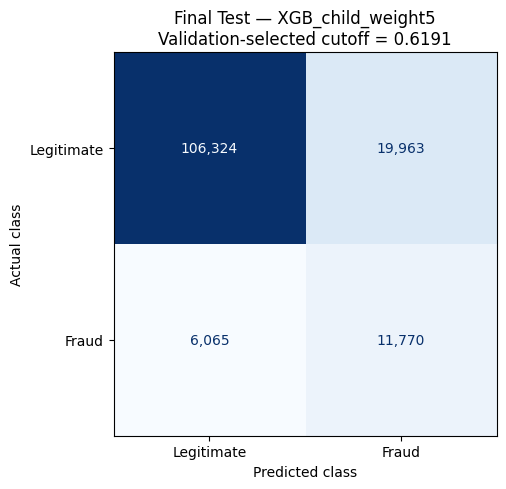

In [22]:
final_test_scores = test_score_dict["Selected configuration"]
final_test_predictions = (
    final_test_scores >= selected_xgb_threshold
).astype(int)

final_cm = confusion_matrix(
    y_test,
    final_test_predictions,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Legitimate", "Fraud"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format=",d",
    colorbar=False
)

ax.set_title(
    f"Final Test — {selected_xgb_run}\n"
    f"Validation-selected cutoff = {selected_xgb_threshold:.4f}"
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
plt.tight_layout()
plt.show()

#### Final Test Results

| Model and cutoff | AP | Fraud precision | Fraud recall | Fraud F1 | Orders flagged |
|---|---:|---:|---:|---:|---:|
| Baseline at `0.5` | 0.4219 | 0.5310 | 0.2168 | 0.3079 | 5.05% |
| Baseline at `0.1420` | 0.4219 | 0.3642 | 0.6664 | 0.4710 | 22.64% |
| `XGB_child_weight5` at `0.5` | 0.4275 | 0.3111 | 0.7511 | 0.4400 | 29.87% |
| **Final model at `0.6191`** | **0.4275** | 0.3709 | 0.6599 | **0.4749** | 22.02% |

- **Effect of tuning the cutoff.** For `XGB_child_weight5`, raising the cutoff from `0.5` to `0.6191` improved test F1 from **0.4400 to 0.4749** and reduced the flagged share from **29.87% to 22.02%**. Recall fell from **75.11% to 65.99%**.
- **Comparison with the tuned baseline.** The final model achieved slightly higher test AP (**0.4275 vs 0.4219**) and F1 (**0.4749 vs 0.4710**). It generated **782 fewer false alerts** and missed **115 more fraudulent orders**.
- **Performance on later orders.** Both models recorded lower AP on test than on validation. The final model retained a small AP lead of **0.0056** on test.

### 7️⃣ Final Conclusion

**Final selection — `XGB_child_weight5` with a decision cutoff of `0.6191`.**

- **Why this model?** `XGB_child_weight5` achieved the highest validation AP (**0.5361**, compared with **0.5282** for the baseline). AP was the selection metric because the model first needs to rank suspicious orders across possible cutoffs.
- **Why this cutoff?** The `0.6191` cutoff maximised fraud F1 on validation. The same cutoff was then applied to the test period, where it achieved **0.4749 F1**, **37.09% precision** and **65.99% recall**, while flagging **22.02%** of orders.
- **What trade-off does the selection make?** The final model offers a slightly better balance of precision and recall by F1, with fewer false alerts to review. The tuned baseline had slightly higher recall (**66.64% vs 65.99%**), so the preferred cutoff for actual use depends on the cost of missed fraud and the team's review capacity.